# Partycjonowanie tabeli cech i benchmark A/B

Milestone 2, zadania 3–4. Uruchom po `04_silver.ipynb` i `05_inz_cech.ipynb`.
Wejście: `data/silver/pm25_pogoda_2024.parquet`. Oba warianty zachowują wszystkie 40 kolumn, wszystkie godziny i NULL-e.

A: jeden plik Parquet. B: katalog Hive `kod_stacji=.../`. Snappy w obu wariantach.
Klucz stacji odpowiada analizie historii konkretnej lokalizacji; tabela obejmuje już tylko PM2.5, więc `wskaznik` nie dzieli jej sensownie. Obecnie 96 stacji ma po 8784 godziny. Równe partycje nie gwarantują krótszego czasu: wiele małych plików też kosztuje.

To pomiar całego zapytania przy rozgrzanym cache systemu, bez jego czyszczenia. `write_statistics=False` w obu wariantach izoluje wpływ pruning plików od statystyk grup wierszy. Źródło jest uporządkowane po stacji: ze statystykami płaski plik także może pomijać grupy. Wyniki dotyczą tego eksperymentu, nie dowodzą przewagi nad produkcyjnym Parquet ze statystykami.


In [1]:
from pathlib import Path
import runpy
import polars as pl
from IPython.display import display, Markdown
cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == 'notebooks' else cwd
benchmark = runpy.run_path(str(ROOT / 'scripts/partition_benchmark.py'))
ctx = benchmark['create_context'](root=ROOT, repeats=20, warmups=3, write_statistics=False)
print('Wejście:', ctx['source'])
print('Raport:', ctx['report'])


Wejście: C:\Users\krysq\Documents\Projekty\gios-bigdata\data\silver\pm25_pogoda_2024.parquet
Raport: C:\Users\krysq\Documents\Projekty\gios-bigdata\reports\partition_benchmark\20261120T233319_013991Z


## 1. Zapis pełnej tabeli cech

Oba zapisy mają ten sam limit wielkości grup wierszy. Rzeczywiste rozmiary, liczba plików i grup są raportowane poniżej; sam limit nie zapewnia identycznego układu fizycznego.


In [2]:
storage = benchmark['write_variants'](ctx)
print(storage['tree'])
display(storage['storage'])
display(storage['files'])


data\benchmark\20261120T233319_013991Z\partitioned/
  kod_stacji=DsChojnowMalMOB/
    part-0.parquet (8,784 wierszy, 500,957 B)
  kod_stacji=DsJelGorOgin/
    part-0.parquet (8,784 wierszy, 494,195 B)
  kod_stacji=DsKlodzSzkol/
    part-0.parquet (8,784 wierszy, 514,772 B)
  kod_stacji=DsKudowaSzkoMOB/
    part-0.parquet (8,784 wierszy, 524,813 B)
  kod_stacji=DsWrocAlWisn/
    part-0.parquet (8,784 wierszy, 511,273 B)
  kod_stacji=DsWrocWybCon/
    part-0.parquet (8,784 wierszy, 493,157 B)
  kod_stacji=KpBydPlPozna/
    part-0.parquet (8,784 wierszy, 535,068 B)
  kod_stacji=KpBydWarszaw/
    part-0.parquet (8,784 wierszy, 551,190 B)
  kod_stacji=KpNaklWawrzy/
    part-0.parquet (8,784 wierszy, 518,925 B)
  kod_stacji=KpSwiecJPawlMOB/
    part-0.parquet (8,784 wierszy, 492,222 B)
  kod_stacji=KpToruKaszow/
    part-0.parquet (8,784 wierszy, 497,587 B)
  kod_stacji=KpWloclOkrze/
    part-0.parquet (8,784 wierszy, 539,446 B)
  kod_stacji=LbLubObywate/
    part-0.parquet (8,784 wierszy, 5

variant,files,rows,bytes
str,i64,i64,i64
"""A""",1,843264,31338263
"""B""",96,843264,49281372


partition,file,rows,bytes,row_groups
str,str,i64,i64,i64
"""kod_stacji=DsChojnowMalMOB""","""part-0.parquet""",8784,500957,1
"""kod_stacji=DsJelGorOgin""","""part-0.parquet""",8784,494195,1
"""kod_stacji=DsKlodzSzkol""","""part-0.parquet""",8784,514772,1
"""kod_stacji=DsKudowaSzkoMOB""","""part-0.parquet""",8784,524813,2
"""kod_stacji=DsWrocAlWisn""","""part-0.parquet""",8784,511273,1
…,…,…,…,…
"""kod_stacji=WpPoznSzwajc""","""part-0.parquet""",8784,532559,2
"""kod_stacji=ZpDabkiSztorMOB""","""part-0.parquet""",8784,491090,1
"""kod_stacji=ZpKolZolkiew""","""part-0.parquet""",8784,499662,1


## 2. Zgodność źródła, A i B

Porównujemy pełne schematy oraz wszystkie wartości przez `EXCEPT ALL` w obie strony, z jawną kolejnością kolumn. Sprawdzamy też unikalność `(kod_stacji, data_czas_utc)`. NULL-e są zachowane, a `kod_stacji` jest odtwarzane z katalogu Hive jako tekst. Test obejmuje również cechy niewykorzystywane przez zapytania benchmarku.


In [3]:
validation = benchmark['verify_data'](ctx)
print(validation)
assert validation['checked_columns'] == 40
assert validation['source_rows'] == 96 * 8784


{'status': 'OK', 'source_rows': 843264, 'A_rows': 843264, 'B_rows': 843264, 'checked_columns': 40}


## 3. Scenariusze i partition pruning

Jedna stacja, 8 stacji, 32 stacje i kontrola bez filtra. Grupy pochodzą z deterministycznego losowania (seed 42). Agregacja wykorzystuje zapisaną lokalną `godzina`, `pm25`, temperaturę i `pm25_lag24`. `count(*)` obejmuje wszystkie godziny, `count(pm25)` tylko dostępne pomiary; średnie pomijają NULL.

Godzina lokalna nie jest kluczem: przy zmianie czasu występuje pominięta lub powtórzona godzina. Dlatego grupy godzin mogą mieć różne liczebności, a klucz unikalności zawsze korzysta z UTC.


In [4]:
scenarios = benchmark['prepare_scenarios'](ctx)
display(scenarios)
for item in ctx['scenarios']:
    print(item['scenario'])
    print((ctx['report'] / f"plan_{item['id']}_B.txt").read_text(encoding='utf-8'))


id,scenario,stations,selected_stations,total_stations
str,str,list[str],i64,i64
"""q01""","""1_stacji""","[""WmDzialPolnaMOB""]",1,96
"""q02""","""8_stacji""","[""WmDzialPolnaMOB"", ""PkMielBierna"", … ""PmGdaWyzwole""]",8,96
"""q03""","""32_stacji""","[""WmDzialPolnaMOB"", ""PkMielBierna"", … ""PdAugustowUz""]",32,96
"""control""","""wszystkie_stacje""",null,96,96


1_stacji
╭─ Summary ───────────╮
│ Total Time: 0.0185s │
│ Data Read:  72.8 kB │
╰─────────────────────╯
╭─ Order By ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Order By: godzina ASC                                                                                                                       │
│ 24 rows                                                                                                                                 0µs │
╰──────────────────────────────────────────────────────────────────────┬──────────────────────────────────────────────────────────────────────╯
╭─ Projection ─────────────────────────────────────────────────────────┴──────────────────────────────────────────────────────────────────────╮
│ Projections: #0, "/"(#1, CAST(#5 AS DOUBLE)), #2, #3, #4, #5                                                                                │
│ 24 rows                      

## 4. Pomiary i zestawienie

Trzy rozgrzewki, 20 powtórzeń, losowana kolejność scenariuszy i A/B, to samo połączenie i liczba wątków. Zapis i walidacja są poza pomiarem. Zysk = `(A − B) / A × 100%`; ujemny wynik oznacza wolniejsze B. SD opisuje rozrzut, nie przedział ufności.


In [5]:
timings = benchmark['run_benchmark'](ctx)
summary = benchmark['summarize'](ctx, timings)
print('Liczba pomiarów:', timings.height)
display(Markdown((ctx['report'] / 'summary.md').read_text(encoding='utf-8')))
display(timings)


Liczba pomiarów: 160


| scenario | repeats | A_mean_ms | B_mean_ms | A_median_ms | B_median_ms | A_std_ms | B_std_ms | time_saved_percent | speedup_A_over_B |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1_stacji | 20 | 3.121 | 14.443 | 3.051 | 14.331 | 0.227 | 0.602 | -362.800 | 0.216 |
| 8_stacji | 20 | 5.836 | 15.713 | 5.690 | 15.489 | 0.779 | 0.891 | -169.255 | 0.371 |
| 32_stacji | 20 | 6.679 | 19.933 | 6.792 | 19.587 | 0.352 | 0.890 | -198.450 | 0.335 |
| wszystkie_stacje | 20 | 5.556 | 21.589 | 5.580 | 21.376 | 0.286 | 0.863 | -288.591 | 0.257 |

id,scenario,iteration,variant,position_in_pair,time_ms,result_rows
str,str,i64,str,i64,f64,i64
"""q03""","""32_stacji""",1,"""B""",1,20.4395,24
"""q03""","""32_stacji""",1,"""A""",2,7.0611,24
"""q02""","""8_stacji""",1,"""B""",1,15.8144,24
"""q02""","""8_stacji""",1,"""A""",2,5.6272,24
"""control""","""wszystkie_stacje""",1,"""B""",1,22.0025,24
…,…,…,…,…,…,…
"""q03""","""32_stacji""",20,"""A""",2,6.3486,24
"""q02""","""8_stacji""",20,"""B""",1,14.9145,24
"""q02""","""8_stacji""",20,"""A""",2,5.7449,24


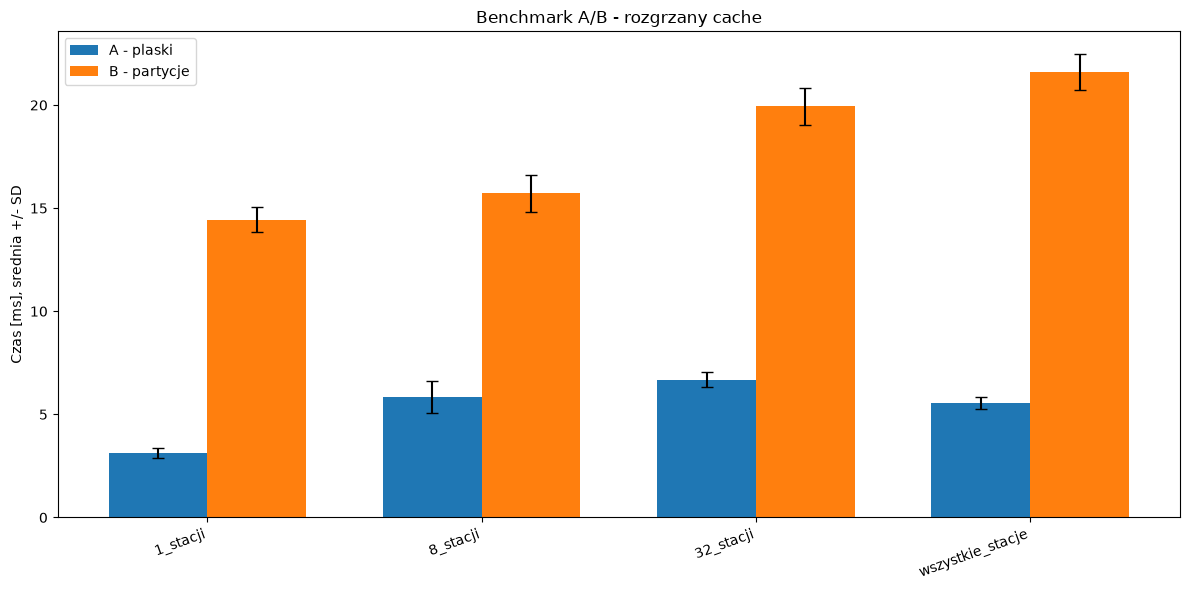

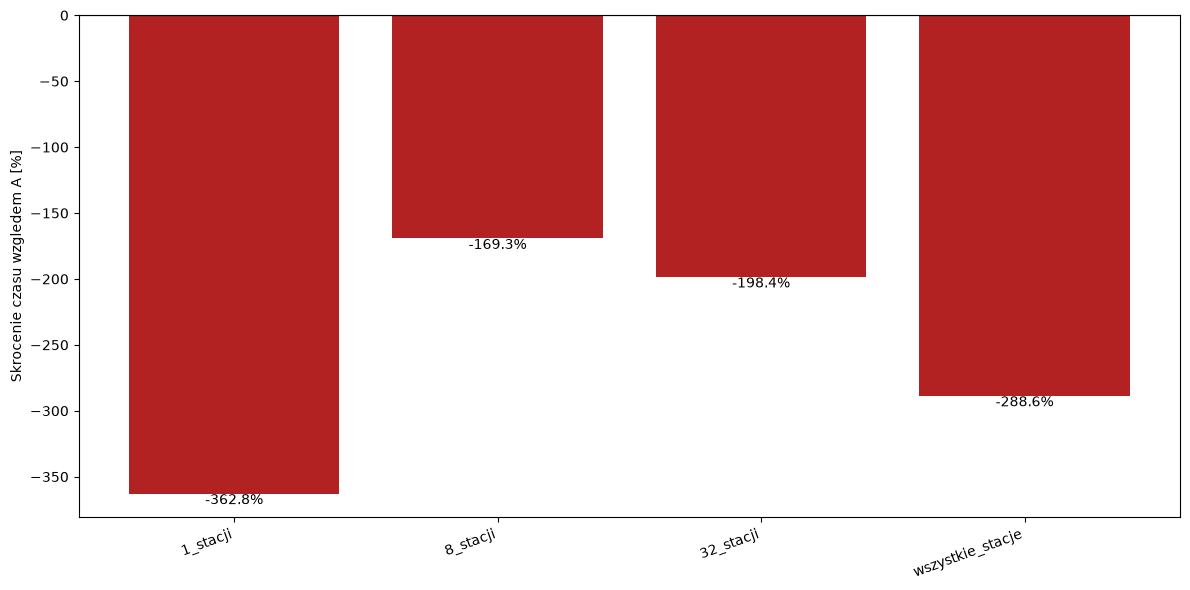

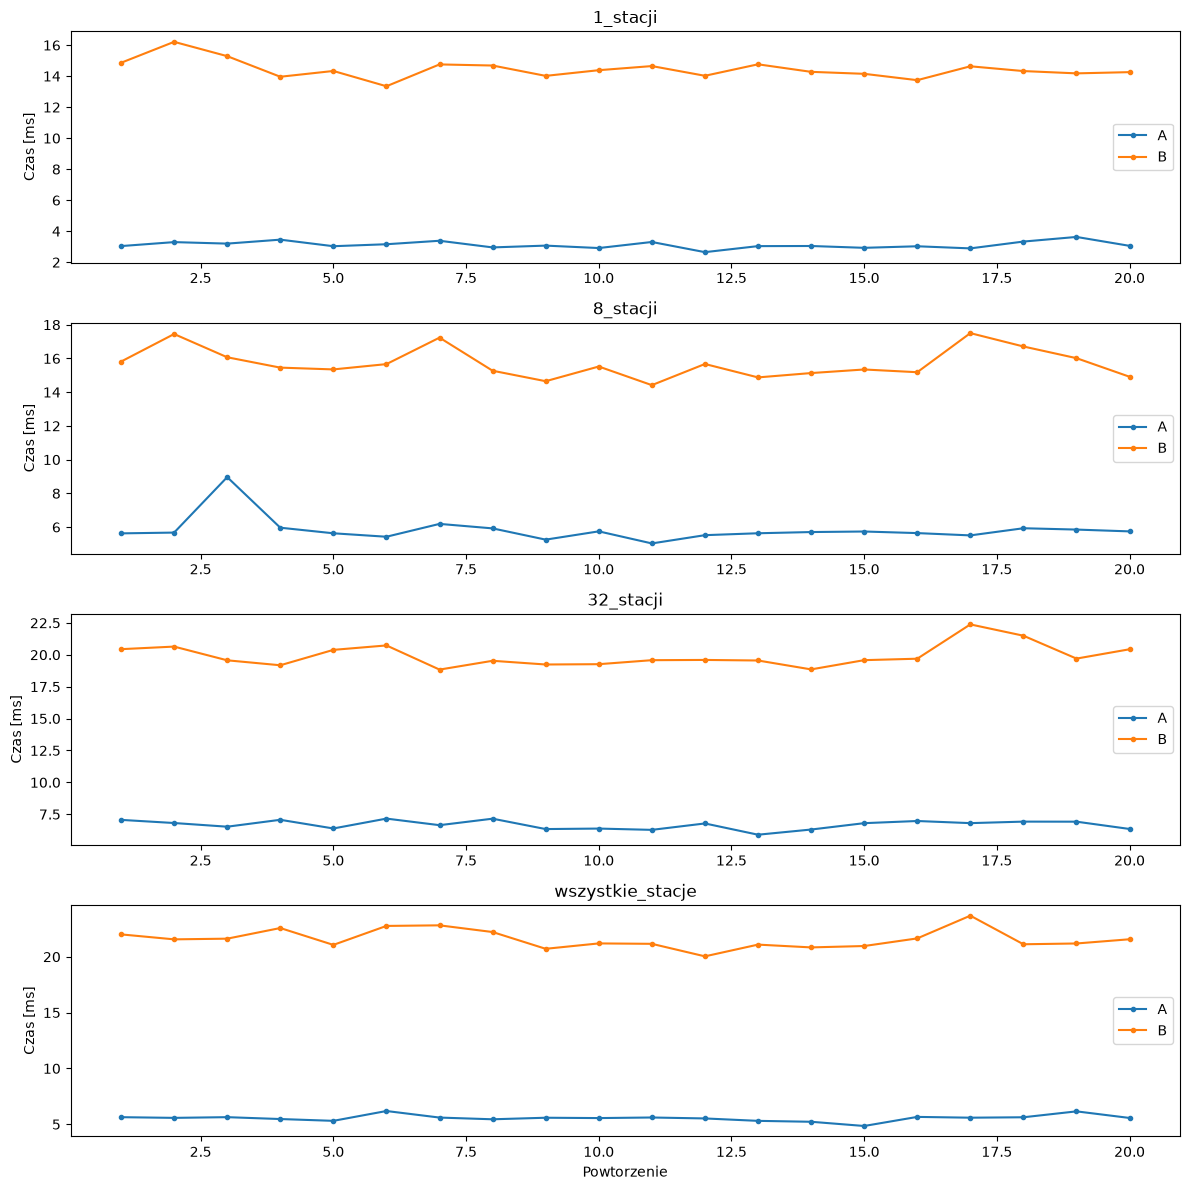

In [6]:
import matplotlib.pyplot as plt
figures = benchmark['make_plots'](ctx, timings, summary)
for figure in figures:
    display(figure)
    plt.close(figure)


## 5. Interpretacja wyników

Poniższe zestawienie pochodzi z bieżącego uruchomienia. Nawet przy działającym pruning B może być wolniejsze z powodu obsługi plików i układu grup. Małe różnice należy interpretować razem z rozrzutem pomiarów. Nie mierzymy osobno transferu dyskowego, kosztów chmury ani zimnego cache.

W zapisanej serii B było wolniejsze we wszystkich czterech scenariuszach, mimo potwierdzonego pruning 1/96, 8/96 i 32/96 plików. Dla kontroli odczytano 96 plików. Zapis B ma 120 grup wierszy: nie każda stacja mieści się w jednej grupie, mimo że limit jest większy od jej liczby wierszy. Rozmiar B jest około 1,57 razy większy od A. Wynik pokazuje, że pomijanie plików samo w sobie nie gwarantuje przyspieszenia tej niewielkiej tabeli; pomiar nie rozdziela kosztu otwierania plików, planowania, grup wierszy i agregacji.


In [7]:
for row in summary.to_dicts():
    print(f"{row['scenario']}: A={row['A_mean_ms']:.3f} ms, B={row['B_mean_ms']:.3f} ms; "
          f"zysk B={row['time_saved_percent']:.2f}%; SD A/B={row['A_std_ms']:.3f}/{row['B_std_ms']:.3f} ms")
a, b = storage['storage'].to_dicts()
print(f"Rozmiar B/A: {b['bytes'] / a['bytes']:.2f}; pliki A/B: {a['files']}/{b['files']}")


1_stacji: A=3.121 ms, B=14.443 ms; zysk B=-362.80%; SD A/B=0.227/0.602 ms
8_stacji: A=5.836 ms, B=15.713 ms; zysk B=-169.25%; SD A/B=0.779/0.891 ms
32_stacji: A=6.679 ms, B=19.933 ms; zysk B=-198.45%; SD A/B=0.352/0.890 ms
wszystkie_stacje: A=5.556 ms, B=21.589 ms; zysk B=-288.59%; SD A/B=0.286/0.863 ms
Rozmiar B/A: 1.57; pliki A/B: 1/96


## 6. Przekazanie do Milestone 3

Po walidacji kopii publikujemy B pod stałą ścieżką. Poprzedni opublikowany katalog pozostaje w katalogu danych tej serii jako `previous_published`. Raporty i warianty eksperymentu mają odrębne datowane katalogi.

W gold filtrujemy brak celu i wybieramy cechy stosownie do horyzontu dopiero po odczycie gotowych cech. Nie przeliczamy lagów na próbie. Dla 24 h nie używamy lagów 1–3 ani okien kończących się na t−1. Weryfikacja modelu powinna stosować podział czasowy; pogoda jest reanalizą, nie rzeczywistą prognozą. Reservoir sampling z całego zbioru nie zyskuje na pruning według stacji.


In [8]:
published = benchmark['publish_dataset'](ctx)
print('Dane dla M3:', published)
reader = f"read_parquet('{published.as_posix()}/**/*.parquet', hive_partitioning=true, hive_types={{'kod_stacji': 'VARCHAR'}})"
print(ctx['con'].execute(f"SELECT count(*), count(pm25), count(DISTINCT kod_stacji) FROM {reader}").fetchall())
assert len(ctx['con'].execute(f'DESCRIBE SELECT * FROM {reader}').fetchall()) == 40
ctx['con'].close()


Dane dla M3: C:\Users\krysq\Documents\Projekty\gios-bigdata\data\silver\pm25_pogoda_2024_partycje
[(843264, 816674, 96)]
